# Iris Flower Classification
**CodeAlpha Machine Learning Internship – Task 1**

**Objective:** Train a machine learning model that classifies Iris flowers into one of three species (*Setosa*, *Versicolor*, *Virginica*) using their measurements.

**Workflow:**
1. Import libraries
2. Load the dataset
3. Explore the data (EDA)
4. Preprocess the data
5. Train/test split
6. Train models
7. Evaluate performance
8. Predict on new data

## Step 1: Import Libraries
We import the libraries we need:
- **NumPy / Pandas** for data handling
- **Matplotlib / Seaborn** for visualization
- **Scikit-learn** for modeling and evaluation

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Plot style
sns.set_style("whitegrid")
%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Load the Dataset
We load `Iris.csv` from the Kaggle input directory into a Pandas DataFrame and look at the first few rows.

In [2]:
file_path = "/kaggle/input/datasets/saurabh00007/iriscsv/Iris.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## Step 3: Data Exploration (EDA)
Before modeling, we need to understand the data. We will check:
1. Column names and data types
2. Summary statistics
3. Missing values and duplicates
4. Class balance (how many samples per species)

In [3]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [4]:
# Summary statistics for the numeric columns
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [5]:
# Missing values and duplicate rows
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 0


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


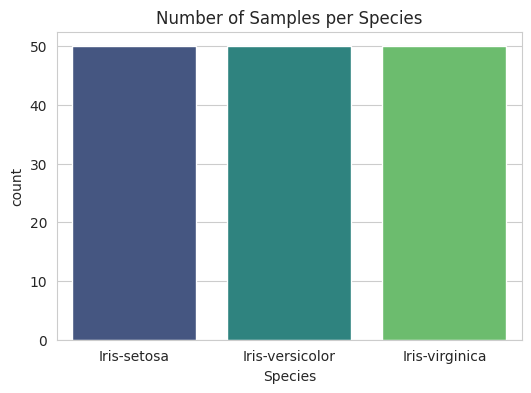

In [6]:
# Class balance
print(df["Species"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x="Species", data=df, palette="viridis")
plt.title("Number of Samples per Species")
plt.show()

## Step 4: Data Visualization
Visualizing the features helps us see how well the species separate from each other, which tells us how easy the classification problem will be.

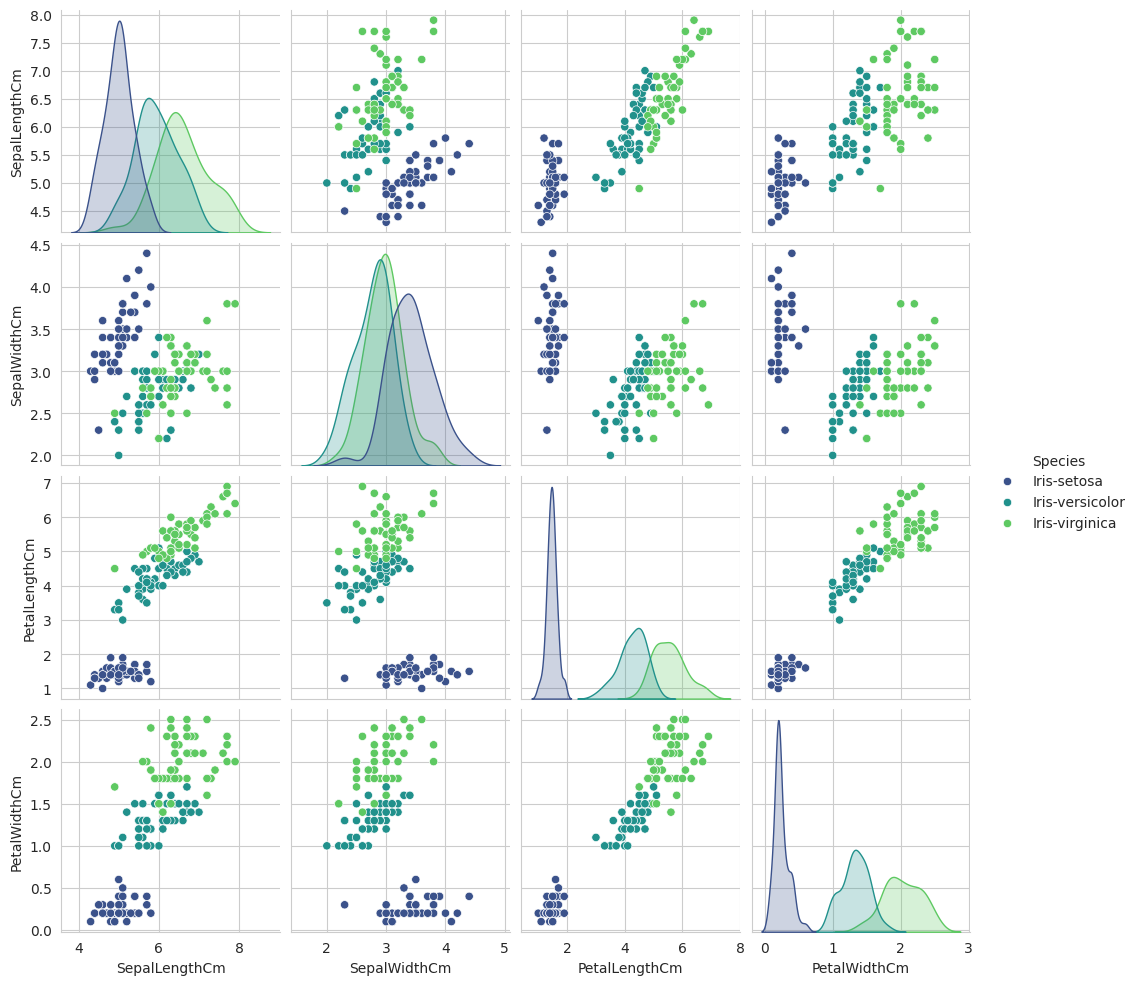

In [7]:
# Pairplot: every feature against every other, colored by species
sns.pairplot(df.drop("Id", axis=1), hue="Species", palette="viridis")
plt.show()

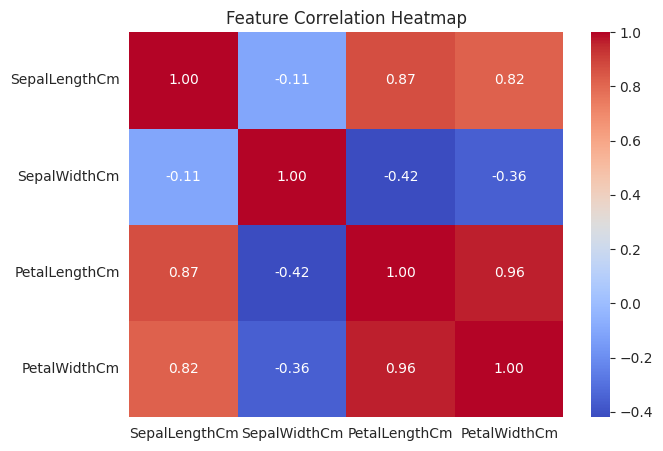

In [8]:
# Correlation heatmap of the four features
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(["Id", "Species"], axis=1).corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

## Step 5: Data Preprocessing
Steps we will take:
1. **Drop the `Id` column**, since it is just a row counter and carries no information about the species.
2. **Separate features (X) and target (y).**
3. **Encode the target labels**, converting species names to numbers (0, 1, 2) because models work with numeric labels.

In [9]:
# 1. Drop the Id column
df = df.drop("Id", axis=1)

# 2. Separate features and target
X = df.drop("Species", axis=1)
y = df["Species"]

# 3. Encode the species names as numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Check the mapping
for number, name in enumerate(le.classes_):
    print(f"{number} -> {name}")

print("\nFeatures shape:", X.shape)
print("Target shape:", y_encoded.shape)
X.head()

0 -> Iris-setosa
1 -> Iris-versicolor
2 -> Iris-virginica

Features shape: (150, 4)
Target shape: (150,)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Step 6: Train/Test Split
We split the data into:
- **Training set (80%)**: used to teach the model
- **Test set (20%)**: kept hidden until the end to evaluate how well the model generalizes

We use `stratify` so each species appears in the same proportion in both sets, and `random_state` so results are reproducible.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)
print("\nClass counts in training set:", np.bincount(y_train))
print("Class counts in test set:    ", np.bincount(y_test))

Training set: (120, 4)
Test set:     (30, 4)

Class counts in training set: [40 40 40]
Class counts in test set:     [10 10 10]


## Step 7: Feature Scaling
Some algorithms (KNN, SVM, Logistic Regression) are sensitive to feature scale, so we standardize the features to mean 0 and standard deviation 1.

**Important:** we fit the scaler on the training data only, then apply it to the test data. Fitting on the test data would leak information and make our evaluation unrealistic.

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)  # learn from training data
X_test_scaled = scaler.transform(X_test)        # apply same scaling to test data

print("Mean of scaled training features:", X_train_scaled.mean(axis=0).round(2))
print("Std of scaled training features: ", X_train_scaled.std(axis=0).round(2))

Mean of scaled training features: [-0.  0. -0.  0.]
Std of scaled training features:  [1. 1. 1. 1.]


## Step 8: Train Multiple Models
We will train five different classifiers and compare them:
1. **Logistic Regression**: a linear model that estimates class probabilities
2. **K-Nearest Neighbors (KNN)**: classifies a flower by looking at its closest neighbors
3. **Decision Tree**: learns a series of if/else rules
4. **Random Forest**: an ensemble of many decision trees voting together
5. **Support Vector Machine (SVM)**: finds the boundary that best separates the classes

Scaled data is used for all of them. Tree-based models don't need scaling, but it doesn't hurt them either.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)               # train
    y_pred = model.predict(X_test_scaled)            # predict on test set
    results[name] = accuracy_score(y_test, y_pred)   # store accuracy
    print(f"{name:20s} Test Accuracy: {results[name]:.4f}")

Logistic Regression  Test Accuracy: 0.9333
KNN                  Test Accuracy: 0.9333
Decision Tree        Test Accuracy: 0.9000
Random Forest        Test Accuracy: 0.9000
SVM                  Test Accuracy: 0.9667


## Step 9: Cross-Validation
A single train/test split can be lucky or unlucky, especially with only 30 test samples. **5-fold cross-validation** is more reliable: the training data is split into 5 parts, and each part takes a turn as the validation set. We then average the 5 scores.

In [13]:
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    cv_results[name] = scores
    print(f"{name:20s} CV Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression  CV Accuracy: 0.9583 (+/- 0.0264)
KNN                  CV Accuracy: 0.9667 (+/- 0.0312)
Decision Tree        CV Accuracy: 0.9417 (+/- 0.0204)
Random Forest        CV Accuracy: 0.9500 (+/- 0.0167)
SVM                  CV Accuracy: 0.9667 (+/- 0.0312)


## Step 10: Compare the Models
A bar chart makes the comparison easy to see.

,Test Accuracy,CV Mean Accuracy
KNN,0.9333,0.9667
SVM,0.9667,0.9667
Logistic Regression,0.9333,0.9583
Random Forest,0.9000,0.9500
Decision Tree,0.9000,0.9417


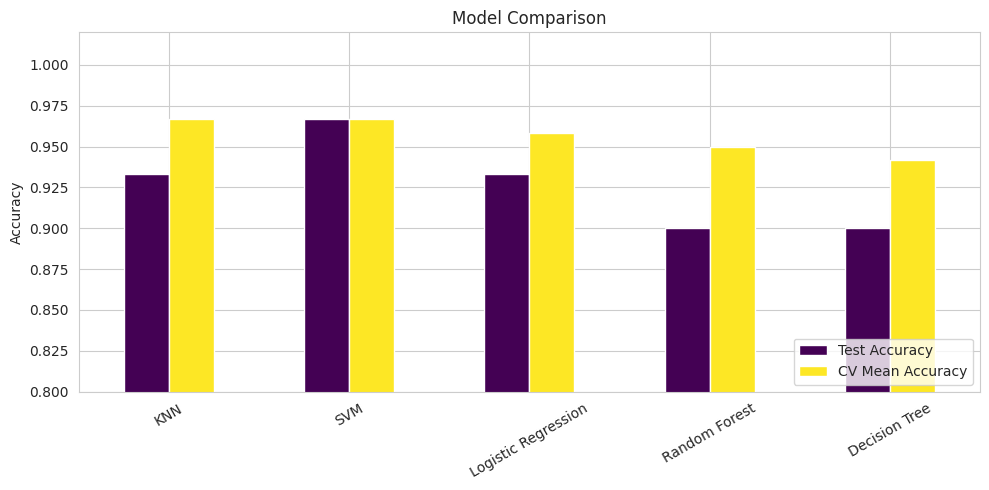

In [14]:
comparison = pd.DataFrame({
    "Test Accuracy": results,
    "CV Mean Accuracy": {k: v.mean() for k, v in cv_results.items()}
}).sort_values("CV Mean Accuracy", ascending=False)

display(comparison.round(4))

comparison.plot(kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.8, 1.02)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Step 11: Detailed Evaluation of the Best Model
Based on the cross-validation results, **SVM** is our best model. Accuracy alone doesn't tell the whole story, so we look at:
- **Classification report**: precision, recall, and F1-score for each species
- **Confusion matrix**: shows exactly which species get confused with which

In [15]:
best_model = models["SVM"]
y_pred = best_model.predict(X_test_scaled)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Test Accuracy: 0.9667

Classification Report:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



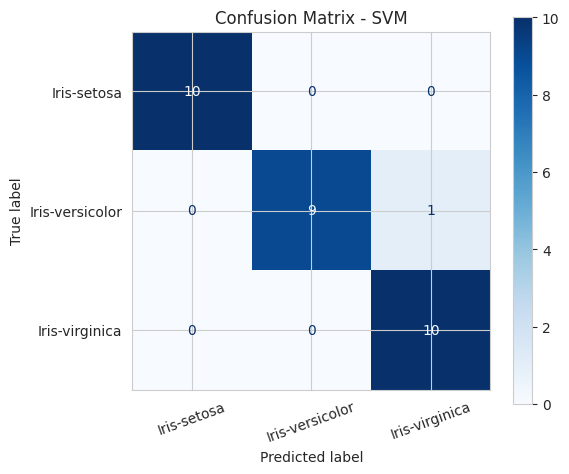

In [16]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
    ax=ax, cmap="Blues", xticks_rotation=20)
plt.title("Confusion Matrix - SVM")
plt.tight_layout()
plt.show()

## Step 12: Predict on a New Flower
Finally, we use the trained model on a brand-new flower measurement. Remember to apply the **same scaler** before predicting.

In [17]:
# Measurements: SepalLength, SepalWidth, PetalLength, PetalWidth (in cm)
new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],    # looks like Setosa
     [6.0, 2.9, 4.5, 1.5],    # looks like Versicolor
     [6.9, 3.1, 5.8, 2.1]],   # looks like Virginica
    columns=X.columns
)

new_scaled = scaler.transform(new_flowers)
predictions = best_model.predict(new_scaled)

for i, p in enumerate(predictions):
    print(f"Flower {i+1}: {le.inverse_transform([p])[0]}")

Flower 1: Iris-setosa
Flower 2: Iris-versicolor
Flower 3: Iris-virginica


## Conclusion

**What I did:**
- Loaded the Iris dataset (150 samples, 4 features, 3 balanced classes) and confirmed it had no missing values or duplicates.
- Explored the data visually and found that petal measurements separate the species best, with Setosa clearly distinct from the other two.
- Dropped the `Id` column, encoded the species labels, split the data 80/20 with stratification, and standardized the features.
- Trained five models: Logistic Regression, KNN, Decision Tree, Random Forest, and SVM.
- Compared them with 5-fold cross-validation, since a 30-sample test set is too small to be a reliable judge on its own.

**Results:**
- **SVM performed best**, with 96.67% cross-validation accuracy and 96.67% test accuracy.
- All five models scored between about 94% and 97%, so the differences between them are small.
- The model correctly classified three new flower measurements.

**Key takeaways:**
- Petal length and width are the most informative features.
- A simple model is often enough on a small, clean dataset.
- Cross-validation gives a more trustworthy comparison than a single split.
- Fitting the scaler on the training data only prevents data leakage.

**Possible improvements:** tune hyperparameters with `GridSearchCV`, try other models, or test on a larger dataset.